# Fraud Risk Intelligence — Modelling Workbook

End-to-end pipeline for the fraud analytics project:

1. **Simulate** a synthetic ledger of 200k card / bank transactions with injected fraud patterns
2. **Profile** data quality and explore fraud concentration by segment
3. **Engineer** calendar, risk-flag, velocity and anomaly features
4. **Export** analysis-ready and MySQL-ready extracts
5. **Model** customer-level fraud propensity (3 classifiers) and tune the decision threshold
6. **Score** every transaction, assign risk tiers and build the Power BI monitoring extracts

## 0. Environment & configuration

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    roc_curve, auc, precision_recall_curve, average_precision_score,
    confusion_matrix, classification_report,
)

SEED = 42

# ---- folder layout -------------------------------------------------------
ROOT_DIR = Path.cwd().parent
DATA_DIR = ROOT_DIR / "Dataset"
RAW_DIR = DATA_DIR / "Raw"
PROCESSED_DIR = DATA_DIR / "Processed"
MODELS_DIR = ROOT_DIR / "Models"

for folder in (RAW_DIR, PROCESSED_DIR, MODELS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

FILES = {
    "raw":              RAW_DIR / "financial_transactions_raw.csv",
    "processed":        PROCESSED_DIR / "financial_transactions_processed.csv",
    "mysql":            PROCESSED_DIR / "financial_transactions_mysql.csv",
    "customer_ml":      PROCESSED_DIR / "customer_ml_features.csv",   # produced by SQL/business_queries.sql
    "predictions":      PROCESSED_DIR / "fraud_transaction_predictions.csv",
    "daily_monitoring": PROCESSED_DIR / "daily_fraud_monitoring.csv",
    "importance":       PROCESSED_DIR / "fraud_model_feature_importance.csv",
}

# ---- business rules ------------------------------------------------------
HOME_COUNTRY = "UK"
DIGITAL_CHANNELS = ["Online", "Mobile"]
HIGH_RISK_TIERS = ["High Risk", "Critical Risk"]
RAPID_WINDOW_MINUTES = 5
NO_PREVIOUS_TXN_MINUTES = 999999
ZSCORE_LIMIT = 3

for label, location in [("Raw", RAW_DIR), ("Processed", PROCESSED_DIR), ("Models", MODELS_DIR)]:
    print(f"{label:<10} -> {location}")

Raw        -> /Users/DELL/Desktop/project2/financial-fraud-risk-analytics-main/Dataset/Raw
Processed  -> /Users/DELL/Desktop/project2/financial-fraud-risk-analytics-main/Dataset/Processed
Models     -> /Users/DELL/Desktop/project2/financial-fraud-risk-analytics-main/Models


## 1. Synthetic transaction ledger

A seeded `RandomState` drives every random draw so the ledger is fully reproducible.
Fraud is injected through three rules that are applied in sequence:

| Rule | Population | Fraud probability |
|---|---|---|
| Big-ticket | amount ≥ 99.5th percentile | 65% (overwrites label) |
| Cross-border digital | Online/Mobile channel **and** non-UK country | +8% |
| Large ATM cash-out | ATM Withdrawal **and** amount > 1,000 | +20% |

In [2]:
N_ROWS = 200_000

# column -> (categories, sampling weights); insertion order == draw order
CATEGORY_SPECS = {
    "transaction_type": (
        ["Purchase", "ATM Withdrawal", "Online Transfer", "Bank Transfer", "Bill Payment"],
        [0.45, 0.15, 0.15, 0.15, 0.10],
    ),
    "channel": (
        ["POS", "Online", "Mobile", "ATM", "Branch"],
        [0.30, 0.30, 0.20, 0.15, 0.05],
    ),
    "country": (
        ["UK", "India", "USA", "Germany", "France", "Singapore", "UAE", "Australia"],
        [0.35, 0.18, 0.15, 0.08, 0.07, 0.06, 0.06, 0.05],
    ),
}


def inject_fraud_labels(ledger: pd.DataFrame, rng: np.random.RandomState) -> np.ndarray:
    """Return a 0/1 fraud label per row using the three rule-based patterns."""
    labels = np.zeros(len(ledger), dtype=np.int64)

    # Rule 1: extreme amounts get a fresh label (65% fraud)
    big_ticket = (ledger["amount"] >= ledger["amount"].quantile(0.995)).to_numpy()
    labels[big_ticket] = rng.choice([0, 1], size=big_ticket.sum(), p=[0.35, 0.65])

    # Rule 2: digital channel used from abroad
    cross_border = (ledger["channel"].isin(DIGITAL_CHANNELS) & ledger["country"].ne(HOME_COUNTRY)).to_numpy()
    labels[cross_border] |= rng.random_sample(cross_border.sum()) < 0.08

    # Rule 3: large ATM withdrawals
    big_atm = (ledger["transaction_type"].eq("ATM Withdrawal") & ledger["amount"].gt(1000)).to_numpy()
    labels[big_atm] |= rng.random_sample(big_atm.sum()) < 0.20

    return labels


def simulate_ledger(n_rows: int, seed: int) -> pd.DataFrame:
    rng = np.random.RandomState(seed)
    ledger = pd.DataFrame({
        "transaction_id": [f"TXN{i:08d}" for i in range(1, n_rows + 1)],
        "customer_id": rng.randint(100_001, 130_001, n_rows),
        "transaction_date": pd.date_range("2024-01-01", "2025-12-31", periods=n_rows),
    })
    for column, (choices, weights) in CATEGORY_SPECS.items():
        ledger[column] = rng.choice(choices, size=n_rows, p=weights)
    ledger["amount"] = np.round(rng.lognormal(mean=3.8, sigma=1.2, size=n_rows), 2)
    ledger["is_fraud"] = inject_fraud_labels(ledger, rng)
    return ledger


ledger = simulate_ledger(N_ROWS, SEED)
ledger.to_csv(FILES["raw"], index=False)

print(f"Ledger written : {FILES['raw'].name}")
print(f"Shape          : {ledger.shape[0]:,} rows x {ledger.shape[1]} columns")
print(f"Fraud labels   : {ledger['is_fraud'].sum():,} ({ledger['is_fraud'].mean() * 100:.2f}%)")
display(ledger.head())

Ledger written : financial_transactions_raw.csv
Shape          : 200,000 rows x 8 columns
Fraud labels   : 5,831 (2.92%)


,transaction_id,customer_id,transaction_date,transaction_type,channel,country,amount,is_fraud
0,TXN00000001,123655,2024-01-01 00:00:00.000000000,Purchase,POS,France,156.11,0
1,TXN00000002,115796,2024-01-01 00:05:15.361576807,Bank Transfer,Mobile,UK,69.84,0
2,TXN00000003,100861,2024-01-01 00:10:30.723153615,Online Transfer,Online,USA,72.78,0
3,TXN00000004,105391,2024-01-01 00:15:46.084730423,ATM Withdrawal,Online,USA,19.85,0
4,TXN00000005,129803,2024-01-01 00:21:01.446307231,Online Transfer,POS,Germany,15.72,0


## 2. Load & data-quality profile

In [3]:
txn = pd.read_csv(FILES["raw"])

quality_profile = pd.DataFrame({
    "dtype": txn.dtypes.astype(str),
    "missing": txn.isna().sum(),
    "distinct": txn.nunique(),
})
print(f"Loaded {txn.shape[0]:,} rows x {txn.shape[1]} columns")
print("Duplicate transaction IDs:", txn["transaction_id"].duplicated().sum())
print("Fully duplicated rows    :", txn.duplicated().sum())
display(quality_profile)
display(txn["amount"].describe().to_frame("amount"))

Loaded 200,000 rows x 8 columns
Duplicate transaction IDs: 0
Fully duplicated rows    : 0


,dtype,missing,distinct
transaction_id,object,0,200000
customer_id,int64,0,29966
transaction_date,object,0,200000
transaction_type,object,0,5
channel,object,0,5
country,object,0,8
amount,float64,0,35371
is_fraud,int64,0,2


,amount
count,200000.000000
mean,92.294202
std,167.958164
min,0.200000
25%,19.900000
50%,44.630000
75%,100.412500
max,11639.090000


## 3. Feature engineering — calendar & transaction flags

In [4]:
txn["transaction_date"] = pd.to_datetime(txn["transaction_date"])
stamp = txn["transaction_date"].dt

txn = txn.assign(
    transaction_year=stamp.year,
    transaction_month=stamp.month,
    transaction_day=stamp.day,
    day_of_week=stamp.dayofweek,
    day_name=stamp.day_name(),
    is_weekend=lambda d: d["day_of_week"].ge(5).astype(int),
)

high_value_cutoff = txn["amount"].quantile(0.95)

txn = txn.assign(
    is_high_value=lambda d: d["amount"].ge(high_value_cutoff).astype(int),
    is_international=lambda d: d["country"].ne(HOME_COUNTRY).astype(int),
    is_digital=lambda d: d["channel"].isin(DIGITAL_CHANNELS).astype(int),
    is_atm=lambda d: d["channel"].eq("ATM").astype(int),
    log_amount=lambda d: np.log1p(d["amount"]),
)

print(f"High-value cut-off (P95): {high_value_cutoff:,.2f}")
display(txn[["transaction_date", "day_name", "is_weekend", "amount",
             "is_high_value", "is_international", "is_digital", "is_atm", "log_amount"]].head())

High-value cut-off (P95): 324.49


,transaction_date,day_name,is_weekend,amount,is_high_value,is_international,is_digital,is_atm,log_amount
0,2024-01-01 00:00:00.000000000,Monday,0,156.11,0,1,0,0,5.056946
1,2024-01-01 00:05:15.361576807,Monday,0,69.84,0,0,1,0,4.260424
2,2024-01-01 00:10:30.723153615,Monday,0,72.78,0,1,1,0,4.301088
3,2024-01-01 00:15:46.084730423,Monday,0,19.85,0,1,1,0,3.037354
4,2024-01-01 00:21:01.446307231,Monday,0,15.72,0,1,0,0,2.816606


## 4. Exploratory fraud analysis

In [5]:
def fraud_breakdown(frame, by, volume_col="transactions", sort_by_rate=False, **extra_metrics):
    """Group by `by`, count rows + frauds, add extra named aggregations and a % fraud rate."""
    table = (
        frame.groupby(by)
        .agg(**{volume_col: ("transaction_id", "count")},
             fraud_transactions=("is_fraud", "sum"),
             **extra_metrics)
        .reset_index()
    )
    table["fraud_rate"] = (table["fraud_transactions"] / table[volume_col] * 100).round(2)
    return table.sort_values("fraud_rate", ascending=False) if sort_by_rate else table


label_mix = pd.DataFrame({
    "count": txn["is_fraud"].value_counts().sort_index(),
    "share_pct": txn["is_fraud"].value_counts(normalize=True).mul(100).round(2),
})
display(label_mix)

display(
    txn.groupby("is_fraud")
    .agg(transaction_count=("transaction_id", "count"),
         average_amount=("amount", "mean"),
         total_amount=("amount", "sum"),
         maximum_amount=("amount", "max"))
    .reset_index()
)

,count,share_pct
is_fraud,,
0,194169,97.08
1,5831,2.92


,is_fraud,transaction_count,average_amount,total_amount,maximum_amount
0,0,194169,87.222976,16935997.99,9037.80
1,1,5831,261.163181,1522842.51,11639.09


In [6]:
by_channel = fraud_breakdown(txn, "channel", sort_by_rate=True,
                             average_amount=("amount", "mean"))

by_country = fraud_breakdown(txn, "country", volume_col="total_transactions", sort_by_rate=True,
                             total_transaction_value=("amount", "sum"),
                             average_transaction_value=("amount", "mean"))

by_type = fraud_breakdown(txn, "transaction_type", volume_col="total_transactions", sort_by_rate=True,
                          total_value=("amount", "sum"),
                          average_amount=("amount", "mean"))

by_value_band = fraud_breakdown(txn, "is_high_value",
                                total_value=("amount", "sum"),
                                average_amount=("amount", "mean"))

for title, table in [("Channel", by_channel), ("Country", by_country),
                     ("Transaction type", by_type), ("High-value flag", by_value_band)]:
    print(f"--- {title} ---")
    display(table)

--- Channel ---


,channel,transactions,fraud_transactions,average_amount,fraud_rate
2,Mobile,40145,2223,92.184883,5.54
3,Online,60076,3292,92.459834,5.48
4,POS,60051,198,92.309605,0.33
1,Branch,9858,32,93.021037,0.32
0,ATM,29870,86,91.837158,0.29


--- Country ---


,country,total_transactions,fraud_transactions,total_transaction_value,average_transaction_value,fraud_rate
2,Germany,15993,722,1453418.52,90.878417,4.51
4,Singapore,11831,524,1096740.22,92.700551,4.43
5,UAE,12116,526,1133079.28,93.519254,4.34
1,France,13920,602,1266161.87,90.959904,4.32
7,USA,30075,1283,2801667.61,93.156030,4.27
0,Australia,10135,426,934080.88,92.163876,4.20
3,India,36030,1505,3334493.66,92.547701,4.18
6,UK,69900,243,6439198.46,92.120150,0.35


--- Transaction type ---


,transaction_type,total_transactions,fraud_transactions,total_value,average_amount,fraud_rate
0,ATM Withdrawal,29843,897,2747557.74,92.067076,3.01
1,Bank Transfer,29984,877,2772614.85,92.469812,2.92
3,Online Transfer,30041,878,2742588.58,91.294850,2.92
4,Purchase,90057,2605,8303364.45,92.201211,2.89
2,Bill Payment,20075,574,1892714.88,94.282186,2.86


--- High-value flag ---


,is_high_value,transactions,fraud_transactions,total_value,average_amount,fraud_rate
0,0,190000,4917,12360652.83,65.056068,2.59
1,1,10000,914,6098187.67,609.818767,9.14


In [7]:
customer_risk = (
    txn.groupby("customer_id")
    .agg(total_transactions=("transaction_id", "count"),
         total_value=("amount", "sum"),
         average_transaction=("amount", "mean"),
         maximum_transaction=("amount", "max"),
         fraud_transactions=("is_fraud", "sum"))
    .reset_index()
)
customer_risk["fraud_rate"] = (customer_risk["fraud_transactions"] / customer_risk["total_transactions"] * 100).round(2)

display(customer_risk.sort_values(["fraud_transactions", "total_value"], ascending=False).head(20))

,customer_id,total_transactions,total_value,average_transaction,maximum_transaction,fraud_transactions,fraud_rate
6775,106785,7,773.44,110.491429,386.83,4,57.14
7447,107459,8,744.85,93.106250,238.76,4,50.00
25479,125512,9,3612.35,401.372222,2019.58,3,33.33
20468,120495,7,3197.31,456.758571,2462.58,3,42.86
19092,119117,10,2897.66,289.766000,1270.93,3,30.00
29829,129864,12,2679.19,223.265833,1128.16,3,25.00
17425,117448,7,2455.47,350.781429,1107.62,3,42.86
5409,105414,15,2403.13,160.208667,1780.06,3,20.00
25961,125995,9,2128.35,236.483333,1292.22,3,33.33
4557,104562,13,1931.47,148.574615,1249.61,3,23.08


## 5. Composite rule-based risk score

In [8]:
RISK_FLAGS = ["is_high_value", "is_international", "is_digital", "is_atm"]
txn["risk_score"] = txn[RISK_FLAGS].sum(axis=1)

display(txn["risk_score"].value_counts().sort_index().rename_axis("risk_score").to_frame("transactions"))

customer_activity = (
    txn.groupby("customer_id")
    .agg(total_transactions=("transaction_id", "count"),
         total_transaction_value=("amount", "sum"),
         average_transaction_value=("amount", "mean"))
    .reset_index()
)
display(customer_activity.head())

,transactions
risk_score,
0,23197
1,87604
2,85010
3,4189


,customer_id,total_transactions,total_transaction_value,average_transaction_value
0,100001,7,454.31,64.901429
1,100002,9,1123.67,124.852222
2,100003,7,475.41,67.915714
3,100004,8,583.42,72.927500
4,100005,6,420.01,70.001667


## 6. Behavioural features — velocity, gaps & amount anomalies

Rows are ordered by customer and timestamp first, so the rolling window and the
previous-transaction lookup operate on each customer's own timeline.

In [9]:
txn = txn.sort_values(["customer_id", "transaction_date"]).reset_index(drop=True)

# number of transactions by the same customer within the trailing 24 hours (inclusive)
rolling_counts = (
    txn.set_index("transaction_date")
    .groupby("customer_id")["transaction_id"]
    .rolling("24h")
    .count()
)
txn["transaction_count_24h"] = rolling_counts.reset_index(level=0, drop=True).values

# gap to the customer's previous transaction
txn["previous_transaction_date"] = txn.groupby("customer_id")["transaction_date"].shift(1)
gap_minutes = (txn["transaction_date"] - txn["previous_transaction_date"]).dt.total_seconds() / 60
txn["minutes_since_previous_transaction"] = gap_minutes.fillna(NO_PREVIOUS_TXN_MINUTES)
txn["is_rapid_transaction"] = txn["minutes_since_previous_transaction"].le(RAPID_WINDOW_MINUTES).astype(int)

display(txn[["customer_id", "transaction_date", "transaction_count_24h",
             "previous_transaction_date", "minutes_since_previous_transaction"]].head(20))
display(fraud_breakdown(txn, "is_rapid_transaction", average_amount=("amount", "mean")))

,customer_id,transaction_date,transaction_count_24h,previous_transaction_date,minutes_since_previous_transaction
0,100001,2024-06-23 12:52:39.879799398,1.0,NaT,999999.000000
1,100001,2024-08-08 14:13:12.255961280,1.0,2024-06-23 12:52:39.879799398,66320.539603
2,100001,2024-09-01 16:12:27.939739700,1.0,2024-08-08 14:13:12.255961280,34679.261396
3,100001,2024-11-25 06:15:37.120685604,1.0,2024-09-01 16:12:27.939739700,121803.153016
4,100001,2025-01-12 04:53:31.432057160,1.0,2024-11-25 06:15:37.120685604,69037.905190
5,100001,2025-01-28 12:01:40.872504360,1.0,2025-01-12 04:53:31.432057160,23468.157341
6,100001,2025-11-20 07:41:35.226476128,1.0,2025-01-28 12:01:40.872504360,425979.905900
7,100002,2024-02-02 10:30:18.333091665,1.0,NaT,999999.000000
8,100002,2024-07-13 14:19:47.105935530,1.0,2024-02-02 10:30:18.333091665,233509.479547
9,100002,2024-07-21 13:38:56.789683948,1.0,2024-07-13 14:19:47.105935530,11479.161396


,is_rapid_transaction,transactions,fraud_transactions,average_amount,fraud_rate
0,0,200000,5831,92.294202,2.92


In [10]:
mu, sigma = txn["amount"].mean(), txn["amount"].std()
txn["amount_z_score"] = (txn["amount"] - mu) / sigma
txn["is_amount_anomaly"] = txn["amount_z_score"].abs().ge(ZSCORE_LIMIT).astype(int)

print(f"Amount anomalies (|z| >= {ZSCORE_LIMIT}): {txn['is_amount_anomaly'].sum():,}")
display(fraud_breakdown(txn, "is_amount_anomaly",
                        average_amount=("amount", "mean"),
                        maximum_amount=("amount", "max")))

Amount anomalies (|z| >= 3): 3,095


,is_amount_anomaly,transactions,fraud_transactions,average_amount,maximum_amount,fraud_rate
0,0,196905,5114,77.720405,596.13,2.60
1,1,3095,717,1019.484407,11639.09,23.17


In [11]:
BEHAVIOUR_FLAGS = ["is_high_value", "is_international", "is_digital",
                   "is_rapid_transaction", "is_amount_anomaly"]
txn["behavioural_risk_score"] = txn[BEHAVIOUR_FLAGS].sum(axis=1)

display(fraud_breakdown(txn, "behavioural_risk_score",
                        average_amount=("amount", "mean"),
                        total_transaction_value=("amount", "sum")))

,behavioural_risk_score,transactions,fraud_transactions,average_amount,total_transaction_value,fraud_rate
0,0,33179,0,64.780845,2149363.65,0.00
1,1,95998,0,69.663969,6687601.69,0.00
2,2,66039,5028,91.629834,6051142.62,7.61
3,3,3796,534,670.259233,2544304.05,14.07
4,4,988,269,1038.895233,1026428.49,27.23


## 7. Extracts for analytics and MySQL

* **processed** – timestamps written as `YYYY-MM-DD HH:MM:SS`, empty cell for a missing previous date
* **mysql** – same rows, missing values encoded as `\N` so `LOAD DATA` imports them as `NULL`

In [12]:
txn.to_csv(FILES["processed"], index=False, date_format="%Y-%m-%d %H:%M:%S")

mysql_extract = txn.copy()
mysql_extract["previous_transaction_date"] = (
    mysql_extract["previous_transaction_date"].dt.strftime("%Y-%m-%d %H:%M:%S").fillna(r"\N")
)
mysql_extract.to_csv(FILES["mysql"], index=False, na_rep=r"\N")

for key in ("processed", "mysql"):
    print(f"{key:<10} exported: {FILES[key].exists()}  ->  {FILES[key]}")

processed  exported: True  ->  /Users/DELL/Desktop/project2/financial-fraud-risk-analytics-main/Dataset/Processed/financial_transactions_processed.csv
mysql      exported: True  ->  /Users/DELL/Desktop/project2/financial-fraud-risk-analytics-main/Dataset/Processed/financial_transactions_mysql.csv


In [13]:
# round-trip check of the MySQL extract
reloaded = pd.read_csv(FILES["mysql"], na_values=r"\N")
print("Shape after reload        :", reloaded.shape)
print("NULL previous dates (\\N) :", reloaded["previous_transaction_date"].isna().sum())
display(reloaded["previous_transaction_date"].head(10).to_frame())

with FILES["mysql"].open(encoding="utf-8") as handle:
    print("".join(next(handle) for _ in range(5)))

Shape after reload        : (200000, 27)
NULL previous dates (\N) : 29966


,previous_transaction_date
0,NaN
1,2024-06-23 12:52:39
2,2024-08-08 14:13:12
3,2024-09-01 16:12:27
4,2024-11-25 06:15:37
5,2025-01-12 04:53:31
6,2025-01-28 12:01:40
7,NaN
8,2024-02-02 10:30:18
9,2024-07-13 14:19:47


transaction_id,customer_id,transaction_date,transaction_type,channel,country,amount,is_fraud,transaction_year,transaction_month,transaction_day,day_of_week,day_name,is_weekend,is_high_value,is_international,is_digital,is_atm,log_amount,risk_score,transaction_count_24h,previous_transaction_date,minutes_since_previous_transaction,is_rapid_transaction,amount_z_score,is_amount_anomaly,behavioural_risk_score
TXN00047819,100001,2024-06-23 12:52:39.879799398,Purchase,ATM,India,88.37,0,2024,6,23,6,Sunday,1,0,1,0,1,4.492785055393301,2,1.0,\N,999999.0,0,-0.02336416640570688,0,1
TXN00060437,100001,2024-08-08 14:13:12.255961280,Online Transfer,POS,India,13.27,0,2024,8,8,3,Thursday,0,0,1,0,0,2.658159431488745,1,1.0,2024-06-23 12:52:39,66320.53960269803,0,-0.47049932241984993,0,1
TXN00067035,100001,2024-09-01 16:12:27.939739700,ATM Withdrawal,Online,Singapore,96.19,0,2024,9,1,6,Sunday,1,0,1,1,0,4.576667825515379,2,1.0,2024-08-08 14:13:12,34679.261396307,0,0.02319504691027974,0,2
TXN00090209,100001,2

## 8. Customer-level fraud propensity models

`customer_ml_features.csv` is built in MySQL (`SQL/business_queries.sql`).
Target = customer has at least one historical fraud. Fields that are derived from the
target itself (`historical_fraud_transactions`, `historical_fraud_rate`) are left out to avoid leakage.

In [14]:
customers = pd.read_csv(FILES["customer_ml"])
customers["fraud_target"] = customers["historical_fraud_transactions"].gt(0).astype(int)

CUSTOMER_FEATURES = [
    "total_transactions", "total_transaction_value",
    "average_transaction_amount", "maximum_transaction_amount",
    "average_transaction_velocity", "maximum_transaction_velocity",
    "rapid_transaction_count", "amount_anomaly_count",
    "international_transaction_count", "digital_transaction_count",
    "average_behavioural_risk_score", "maximum_behavioural_risk_score",
]
X_cust = customers[CUSTOMER_FEATURES].copy()
y_cust = customers["fraud_target"].copy()

class_balance = pd.DataFrame({
    "count": y_cust.value_counts().sort_index(),
    "percentage": y_cust.value_counts(normalize=True).sort_index().mul(100).round(2),
}).rename_axis("class").reset_index()

print(f"Customers: {len(customers):,} | features: {X_cust.shape[1]}")
print(f"Imbalance ratio (non-fraud : fraud) = {(y_cust == 0).sum() / (y_cust == 1).sum():.2f}")
display(class_balance)

Customers: 1,000 | features: 12
Imbalance ratio (non-fraud : fraud) = 4.35


,class,count,percentage
0,0,813,81.3
1,1,187,18.7


In [15]:
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_cust, y_cust, test_size=0.20, random_state=SEED, stratify=y_cust
)
print(f"Train: {len(Xc_train):,} rows ({yc_train.mean() * 100:.2f}% fraud)")
print(f"Test : {len(Xc_test):,} rows ({yc_test.mean() * 100:.2f}% fraud)")

Train: 800 rows (18.75% fraud)
Test : 200 rows (18.50% fraud)


In [16]:
FOREST_PARAMS = dict(n_estimators=300, max_depth=12, min_samples_split=10,
                     min_samples_leaf=5, random_state=SEED, n_jobs=-1)

customer_models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)),
    ]),
    "Random Forest": RandomForestClassifier(class_weight="balanced", **FOREST_PARAMS),
    "Balanced Random Forest": BalancedRandomForestClassifier(**FOREST_PARAMS),
}

test_outputs = {}   # model name -> (hard labels, fraud probability)
for name, estimator in customer_models.items():
    estimator.fit(Xc_train, yc_train)
    test_outputs[name] = (estimator.predict(Xc_test), estimator.predict_proba(Xc_test)[:, 1])
    print(f"trained: {name}")

trained: Logistic Regression


trained: Random Forest


trained: Balanced Random Forest


In [17]:
def scorecard(y_true, y_pred, y_prob):
    return {
        "Accuracy":  accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall":    recall_score(y_true, y_pred, zero_division=0),
        "F1 Score":  f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC":   roc_auc_score(y_true, y_prob),
    }


leaderboard = pd.DataFrame(
    [{"Model": name, **scorecard(yc_test, preds, probs)} for name, (preds, probs) in test_outputs.items()]
).round(4)
display(leaderboard)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.715,0.3485,0.6216,0.4466,0.7233
1,Random Forest,0.805,0.4737,0.4865,0.4800,0.7390
2,Balanced Random Forest,0.740,0.3810,0.6486,0.4800,0.7269


### Explainability & curves (customer Random Forest)

,feature,importance
0,average_behavioural_risk_score,0.2012
1,maximum_transaction_amount,0.1677
2,total_transaction_value,0.1601
3,average_transaction_amount,0.1524
4,digital_transaction_count,0.0948
5,international_transaction_count,0.0896
6,total_transactions,0.0765
7,maximum_behavioural_risk_score,0.0354
8,average_transaction_velocity,0.0093
9,amount_anomaly_count,0.0066


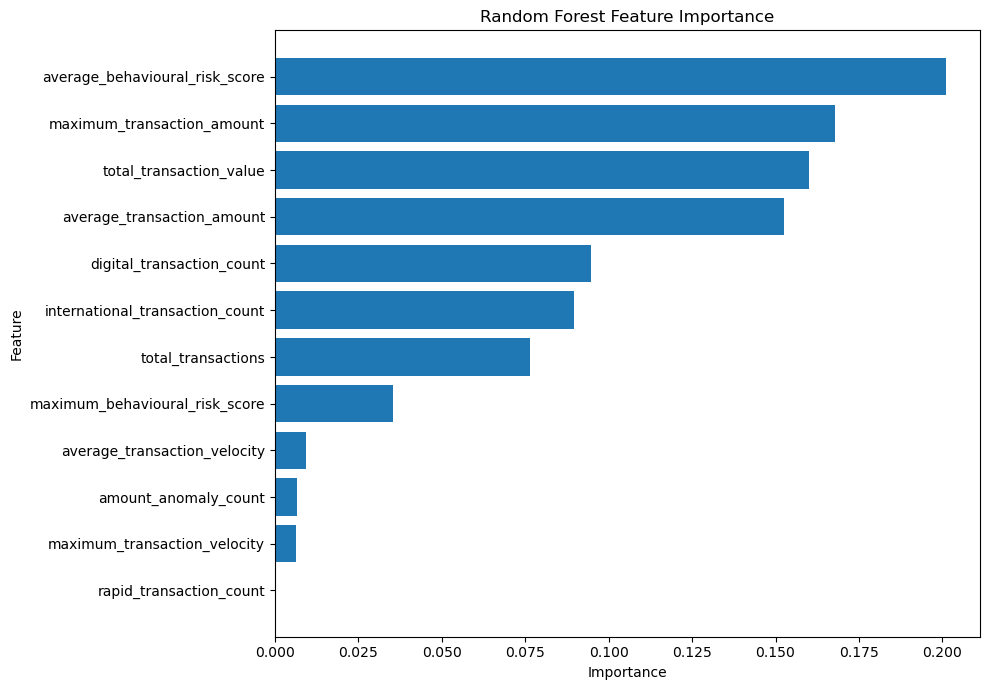

In [18]:
def importance_table(features, model):
    table = pd.DataFrame({"feature": features, "importance": model.feature_importances_})
    table = table.sort_values("importance", ascending=False).reset_index(drop=True)
    table["importance"] = table["importance"].round(4)
    return table


def plot_importance(table, title):
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(table["feature"], table["importance"])
    ax.invert_yaxis()
    ax.set(xlabel="Importance", ylabel="Feature", title=title)
    fig.tight_layout()
    fig.savefig(MODELS_DIR / f"{title}.png", dpi=100)
    plt.show()


customer_forest = customer_models["Random Forest"]
customer_importance = importance_table(X_cust.columns, customer_forest)
display(customer_importance)
plot_importance(customer_importance, "Random Forest Feature Importance")

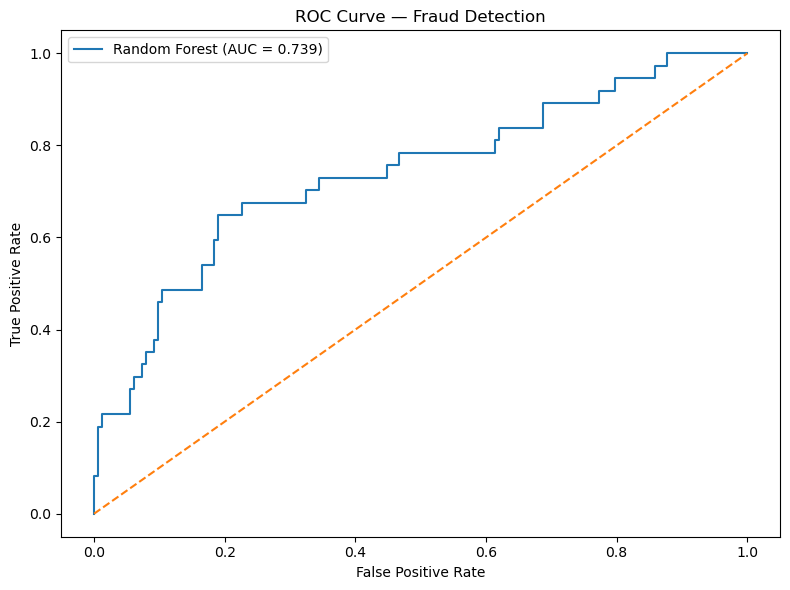

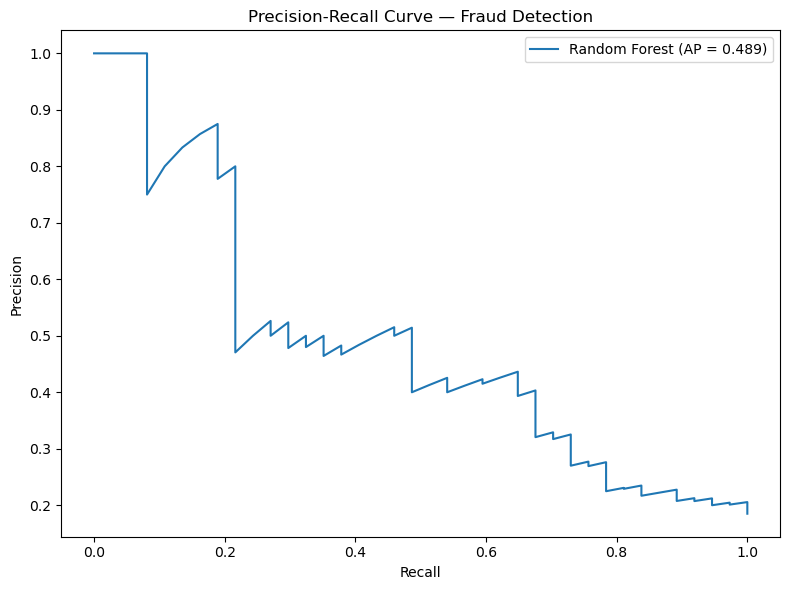

In [19]:
rf_test_prob = test_outputs["Random Forest"][1]

fpr, tpr, _ = roc_curve(yc_test, rf_test_prob)
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(fpr, tpr, label=f"Random Forest (AUC = {auc(fpr, tpr):.3f})")
ax.plot([0, 1], [0, 1], linestyle="--")
ax.set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="ROC Curve — Fraud Detection")
ax.legend()
fig.tight_layout()
fig.savefig(MODELS_DIR / "ROC Curve — Fraud Detection.png", dpi=100)
plt.show()

precision_pts, recall_pts, _ = precision_recall_curve(yc_test, rf_test_prob)
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(recall_pts, precision_pts,
        label=f"Random Forest (AP = {average_precision_score(yc_test, rf_test_prob):.3f})")
ax.set(xlabel="Recall", ylabel="Precision", title="Precision-Recall Curve — Fraud Detection")
ax.legend()
fig.tight_layout()
fig.savefig(MODELS_DIR / "Precision-Recall Curve — Fraud Detection.png", dpi=100)
plt.show()

### Decision-threshold sweep (0.10 → 0.90)

In [20]:
def sweep_thresholds(y_true, probabilities, grid):
    rows = []
    for cut in grid:
        flagged = (probabilities >= cut).astype(int)
        rows.append({
            "threshold": round(cut, 2),
            "precision": precision_score(y_true, flagged, zero_division=0),
            "recall":    recall_score(y_true, flagged, zero_division=0),
            "f1_score":  f1_score(y_true, flagged, zero_division=0),
        })
    return pd.DataFrame(rows).round(4)


threshold_grid = sweep_thresholds(yc_test, rf_test_prob, np.arange(0.10, 0.91, 0.05))
display(threshold_grid)

best = threshold_grid.loc[threshold_grid["f1_score"].idxmax()]
print(f"Best F1 threshold : {best['threshold']}")
print(f"  precision {best['precision']} | recall {best['recall']} | F1 {best['f1_score']}")

,threshold,precision,recall,f1_score
0,0.10,0.2083,0.9459,0.3415
1,0.15,0.2230,0.8919,0.3568
2,0.20,0.2331,0.8378,0.3647
3,0.25,0.2397,0.7838,0.3671
4,0.30,0.2700,0.7297,0.3942
5,0.35,0.3247,0.6757,0.4386
6,0.40,0.3968,0.6757,0.5000
7,0.45,0.4151,0.5946,0.4889
8,0.50,0.4737,0.4865,0.4800
9,0.55,0.4667,0.3784,0.4179


Best F1 threshold : 0.4
  precision 0.3968 | recall 0.6757 | F1 0.5


## 9. Transaction-level fraud scoring model

In [21]:
TXN_FEATURES = [
    "amount", "is_high_value", "is_international", "is_digital", "is_atm",
    "transaction_count_24h", "minutes_since_previous_transaction", "is_rapid_transaction",
    "amount_z_score", "is_amount_anomaly", "risk_score", "behavioural_risk_score", "is_weekend",
]
X_txn = txn[TXN_FEATURES].copy()
y_txn = txn["is_fraud"].copy()

Xt_train, Xt_test, yt_train, yt_test = train_test_split(
    X_txn, y_txn, test_size=0.20, random_state=SEED, stratify=y_txn
)

txn_forest = RandomForestClassifier(class_weight="balanced", **FOREST_PARAMS)
txn_forest.fit(Xt_train, yt_train)
print(f"Transaction model trained on {Xt_train.shape[0]:,} rows x {Xt_train.shape[1]} features")

Transaction model trained on 160,000 rows x 13 features


In [22]:
yt_pred = txn_forest.predict(Xt_test)
yt_prob = txn_forest.predict_proba(Xt_test)[:, 1]

print("Transaction-Level Random Forest")
print("=" * 45)
for metric, value in scorecard(yt_test, yt_pred, yt_prob).items():
    print(f"{metric:<10}: {value:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(yt_test, yt_pred))
print("\nClassification Report:")
print(classification_report(yt_test, yt_pred, zero_division=0))

Transaction-Level Random Forest
Accuracy  : 0.7026
Precision : 0.0883
Recall    : 0.9863
F1 Score  : 0.1620
ROC-AUC   : 0.8634

Confusion Matrix:
[[26956 11878]
 [   16  1150]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.69      0.82     38834
           1       0.09      0.99      0.16      1166

    accuracy                           0.70     40000
   macro avg       0.54      0.84      0.49     40000
weighted avg       0.97      0.70      0.80     40000



,feature,importance
0,behavioural_risk_score,0.3742
1,risk_score,0.2376
2,is_digital,0.1333
3,is_international,0.0827
4,amount_z_score,0.0493
5,amount,0.0485
6,is_atm,0.0357
7,is_amount_anomaly,0.0189
8,minutes_since_previous_transaction,0.0100
9,is_high_value,0.0088


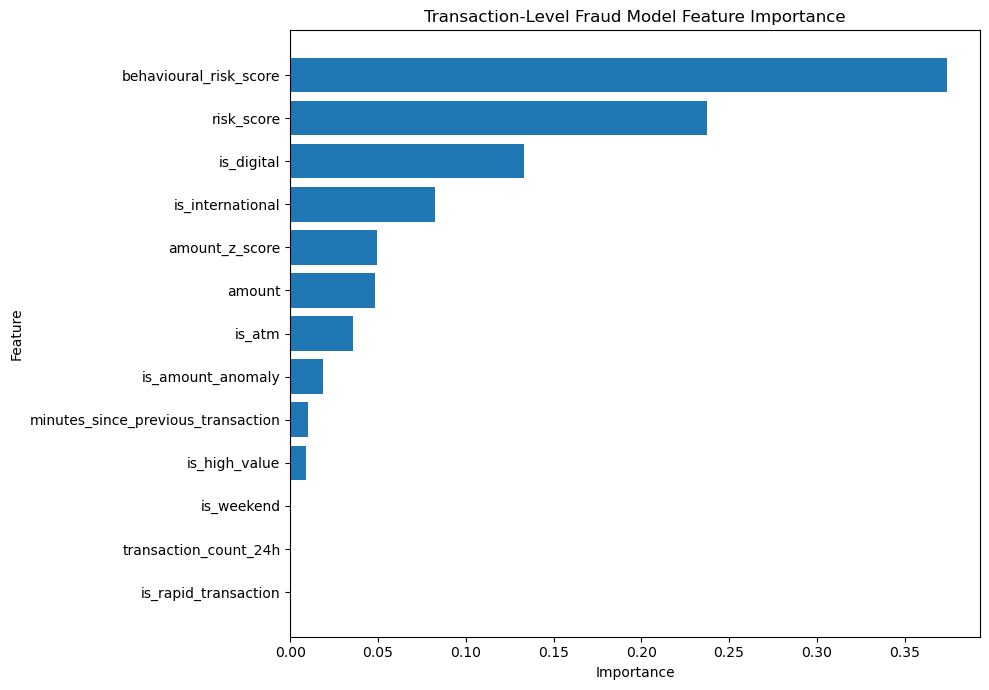

In [23]:
txn_importance = importance_table(TXN_FEATURES, txn_forest)
display(txn_importance)
plot_importance(txn_importance, "Transaction-Level Fraud Model Feature Importance")

## 10. Portfolio scoring & risk tiers

| Probability | Tier |
|---:|---|
| ≤ 0.25 | Low Risk |
| 0.25 – 0.50 | Medium Risk |
| 0.50 – 0.75 | High Risk |
| > 0.75 | Critical Risk |

In [24]:
ID_COLUMNS = ["transaction_id", "customer_id", "transaction_date", "transaction_type",
              "channel", "country", "amount", "is_fraud"]

scored = txn[ID_COLUMNS].copy()
scored["fraud_probability"] = txn_forest.predict_proba(X_txn)[:, 1]
scored["model_prediction"] = txn_forest.predict(X_txn)
scored["risk_category"] = pd.cut(
    scored["fraud_probability"],
    bins=[-0.01, 0.25, 0.50, 0.75, 1.00],
    labels=["Low Risk", "Medium Risk", "High Risk", "Critical Risk"],
)
display(scored["risk_category"].value_counts().to_frame("transactions"))

is_priority = scored["risk_category"].isin(HIGH_RISK_TIERS)
investigation_queue = scored[is_priority].sort_values(["fraud_probability", "amount"], ascending=False)
print(f"High/Critical risk transactions: {len(investigation_queue):,}")
display(investigation_queue.head(25))

large_and_risky = scored[is_priority & scored["amount"].ge(scored["amount"].quantile(0.95))]
display(large_and_risky.sort_values("amount", ascending=False).head(25))

,transactions
risk_category,
Low Risk,134172
High Risk,60591
Critical Risk,4405
Medium Risk,832


High/Critical risk transactions: 64,996


,transaction_id,customer_id,transaction_date,transaction_type,channel,country,amount,is_fraud,fraud_probability,model_prediction,risk_category
125233,TXN00022003,118821,2024-03-21 07:23:05.412927064,Purchase,Online,India,1295.97,1,0.993399,1,Critical Risk
69027,TXN00153918,110427,2025-07-15 19:11:47.817539088,Bank Transfer,Online,Australia,1364.84,1,0.993095,1,Critical Risk
9481,TXN00081548,101445,2024-10-24 15:33:10.503952520,Bank Transfer,Mobile,USA,1320.28,1,0.993077,1,Critical Risk
11207,TXN00088181,101711,2024-11-17 20:36:23.842919216,Purchase,Online,UK,1104.29,1,0.993069,1,Critical Risk
181685,TXN00064262,127255,2024-08-22 13:17:30.287251436,Bill Payment,Online,France,1380.01,1,0.992758,1,Critical Risk
176600,TXN00015949,126484,2024-02-28 05:03:06.426932135,Purchase,Mobile,India,1377.71,1,0.992639,1,Critical Risk
17582,TXN00138561,102666,2025-05-20 17:55:00.082500408,Purchase,Mobile,Singapore,1277.93,1,0.992534,1,Critical Risk
172211,TXN00184468,125836,2025-11-04 07:23:23.989019944,Purchase,Online,UAE,2204.77,1,0.992515,1,Critical Risk
27472,TXN00109060,104165,2025-02-02 01:36:58.205091024,Purchase,Online,UK,1127.52,1,0.992453,1,Critical Risk
19137,TXN00119098,102896,2025-03-10 16:56:57.713088568,Purchase,Mobile,UAE,2205.83,1,0.992322,1,Critical Risk


,transaction_id,customer_id,transaction_date,transaction_type,channel,country,amount,is_fraud,fraud_probability,model_prediction,risk_category
40052,TXN00168606,106037,2025-09-07 09:52:18.657693288,Purchase,Mobile,Australia,11639.09,1,0.965367,1,Critical Risk
105497,TXN00080534,115884,2024-10-20 22:43:33.865069324,Bill Payment,Mobile,UK,9037.80,0,0.968560,1,Critical Risk
93043,TXN00032764,114008,2024-04-29 14:03:11.340956704,Bill Payment,POS,India,8544.17,0,0.952054,1,Critical Risk
185959,TXN00180912,127889,2025-10-22 07:52:58.221891112,Purchase,Mobile,USA,6844.37,0,0.966815,1,Critical Risk
44103,TXN00009949,106655,2024-02-06 07:26:56.966084830,ATM Withdrawal,Online,UK,6280.76,1,0.973275,1,Critical Risk
127302,TXN00028769,119132,2024-04-15 00:05:21.841609208,Bank Transfer,Online,Australia,6158.73,1,0.967442,1,Critical Risk
152585,TXN00026937,122917,2024-04-08 07:36:19.432897164,Purchase,Online,Germany,5948.55,0,0.962328,1,Critical Risk
19094,TXN00059300,102888,2024-08-04 10:37:06.143130716,Bill Payment,Mobile,USA,5695.04,0,0.950682,1,Critical Risk
170569,TXN00158313,125581,2025-07-31 20:12:01.947609736,Purchase,Mobile,India,5312.50,1,0.975155,1,Critical Risk
17671,TXN00070345,102678,2024-09-13 18:09:54.758973796,Bank Transfer,Online,India,4777.16,0,0.984923,1,Critical Risk


## 11. Power BI monitoring extracts

In [25]:
booked_at = pd.to_datetime(scored["transaction_date"])

monitoring = scored.assign(
    transaction_year=booked_at.dt.year,
    transaction_month=booked_at.dt.month,
    transaction_day=booked_at.dt.day,
    is_actual_fraud=scored["is_fraud"],
    correct_prediction=scored["model_prediction"].eq(scored["is_fraud"]).astype(int),
    potential_exposure=np.where(scored["risk_category"].isin(HIGH_RISK_TIERS), scored["amount"], 0),
)
display(monitoring.head(10))

,transaction_id,customer_id,transaction_date,transaction_type,channel,country,amount,is_fraud,fraud_probability,model_prediction,risk_category,transaction_year,transaction_month,transaction_day,is_actual_fraud,correct_prediction,potential_exposure
0,TXN00047819,100001,2024-06-23 12:52:39.879799398,Purchase,ATM,India,88.37,0,0.000000,0,Low Risk,2024,6,23,0,1,0.00
1,TXN00060437,100001,2024-08-08 14:13:12.255961280,Online Transfer,POS,India,13.27,0,0.000000,0,Low Risk,2024,8,8,0,1,0.00
2,TXN00067035,100001,2024-09-01 16:12:27.939739700,ATM Withdrawal,Online,Singapore,96.19,0,0.727190,1,High Risk,2024,9,1,0,0,96.19
3,TXN00090209,100001,2024-11-25 06:15:37.120685604,Purchase,Online,UK,15.80,0,0.000000,0,Low Risk,2024,11,25,0,1,0.00
4,TXN00103344,100001,2025-01-12 04:53:31.432057160,Bank Transfer,ATM,Germany,169.00,0,0.000000,0,Low Risk,2025,1,12,0,1,0.00
5,TXN00107809,100001,2025-01-28 12:01:40.872504360,ATM Withdrawal,Mobile,UK,58.37,0,0.000000,0,Low Risk,2025,1,28,0,1,0.00
6,TXN00188855,100001,2025-11-20 07:41:35.226476128,Bill Payment,Mobile,UAE,13.31,0,0.707298,1,High Risk,2025,11,20,0,0,13.31
7,TXN00008888,100002,2024-02-02 10:30:18.333091665,ATM Withdrawal,Online,UK,53.28,0,0.000000,0,Low Risk,2024,2,2,0,1,0.00
8,TXN00053315,100002,2024-07-13 14:19:47.105935530,Purchase,POS,UK,12.80,0,0.000000,0,Low Risk,2024,7,13,0,1,0.00
9,TXN00055499,100002,2024-07-21 13:38:56.789683948,Bill Payment,ATM,UK,6.20,0,0.000000,0,Low Risk,2024,7,21,0,1,0.00


In [26]:
calendar_day = monitoring["transaction_date"].dt.date

daily_monitoring = (
    monitoring.assign(_flagged=monitoring["risk_category"].isin(HIGH_RISK_TIERS))
    .groupby(calendar_day)
    .agg(total_transactions=("transaction_id", "count"),
         actual_fraud_transactions=("is_actual_fraud", "sum"),
         predicted_high_risk_transactions=("_flagged", "sum"),
         total_transaction_value=("amount", "sum"),
         potential_exposure=("potential_exposure", "sum"))
    .reset_index()
)

fraud_value_by_day = monitoring[monitoring["is_actual_fraud"].eq(1)].groupby(calendar_day)["amount"].sum()
daily_monitoring.insert(
    daily_monitoring.columns.get_loc("potential_exposure"),
    "actual_fraud_value",
    daily_monitoring["transaction_date"].map(fraud_value_by_day).fillna(0),
)
daily_monitoring["fraud_rate"] = (
    daily_monitoring["actual_fraud_transactions"] / daily_monitoring["total_transactions"] * 100
).round(4)
display(daily_monitoring.head())

,transaction_date,total_transactions,actual_fraud_transactions,predicted_high_risk_transactions,total_transaction_value,actual_fraud_value,potential_exposure,fraud_rate
0,2024-01-01,274,9,96,29555.17,3748.64,13465.16,3.2847
1,2024-01-02,274,4,85,28242.49,428.94,9735.63,1.4599
2,2024-01-03,274,6,82,24620.40,1978.00,7679.84,2.1898
3,2024-01-04,274,4,82,20396.70,372.77,5699.72,1.4599
4,2024-01-05,274,9,70,27241.83,3446.72,9836.39,3.2847


In [27]:
exports = {
    "predictions": monitoring,
    "daily_monitoring": daily_monitoring,
    "importance": txn_importance,
}
for key, frame in exports.items():
    frame.to_csv(FILES[key], index=False)
    print(f"{key:<17} {FILES[key].exists()!s:<5} -> {FILES[key]}")

predictions       True  -> /Users/DELL/Desktop/project2/financial-fraud-risk-analytics-main/Dataset/Processed/fraud_transaction_predictions.csv
daily_monitoring  True  -> /Users/DELL/Desktop/project2/financial-fraud-risk-analytics-main/Dataset/Processed/daily_fraud_monitoring.csv
importance        True  -> /Users/DELL/Desktop/project2/financial-fraud-risk-analytics-main/Dataset/Processed/fraud_model_feature_importance.csv
